# Технологии нейросетевых вычислений
## ЛР3. Перенос обучения и семантическая сегментация

**Задание 1.** Классификация изображений ImageNet на 3 метакласса с помощью предобученной сети (fixed feature extractor и fine-tuning).

**Задание 2 (по выбору).** Семантическая сегментация полипов на эндоскопических снимках (Kvasir-SEG) с помощью U-Net и сравнение с классическими методами без нейросетей.

Ноутбук рассчитан на Google Colab с GPU (T4). Обе части независимы: у каждой свой блок загрузки данных, их можно запускать по отдельности.

In [1]:
import os
import io
import time
import copy
import json
import random
import zipfile
import urllib.request
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torchvision
from torchvision import models, tv_tensors
from torchvision.transforms import v2

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report


def set_seed(seed: int = 42) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)


set_seed(42)

if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')
USE_AMP = device.type == 'cuda'
torch.backends.cudnn.benchmark = True  # подбор самых быстрых алгоритмов свёртки под размеры входа
CHANNELS_LAST = torch.channels_last if device.type == 'cuda' else torch.contiguous_format
NUM_WORKERS = min(4, os.cpu_count() or 1) if device.type == 'cuda' else 0

# Рабочие данные — на локальном диске колаба: чтение тысяч мелких файлов с Google Drive очень медленное
DATA_DIR = os.environ.get('LAB3_DATA', '/content/lab3_data')
# Быстрый режим для проверки, что весь код отрабатывает (меньше данных и эпох)
QUICK = os.environ.get('LAB3_QUICK') == '1'
os.makedirs(DATA_DIR, exist_ok=True)

# Прогресс (архив скачанных данных, чекпоинты, результаты экспериментов) сохраняем на Google Drive:
# если колаб отключится, после перезапуска ноутбук продолжит с того же места
SAVE_DIR = os.environ.get('LAB3_SAVE')
if SAVE_DIR is None:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
        SAVE_DIR = '/content/drive/MyDrive/ITMO/TNC/lab3'
    except ImportError:
        SAVE_DIR = os.path.join(DATA_DIR, 'save')
os.makedirs(SAVE_DIR, exist_ok=True)

print('device:', device, '| torch', torch.__version__, '| torchvision', torchvision.__version__, '| QUICK =', QUICK)
print('прогресс сохраняется в', SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cuda | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | QUICK = False
прогресс сохраняется в /content/drive/MyDrive/ITMO/TNC/lab3


# Задание 1. Классификация на 3 метакласса

## 1.1. Метаклассы

Каждый метакласс — осмысленное объединение 5 исходных классов ImageNet (в скобках — индекс класса в ImageNet-1k):

| Метакласс | Классы ImageNet |
|---|---|
| **Грибы** | agaric (992), gyromitra (993), stinkhorn (994), earthstar (995), bolete (997) |
| **Фрукты** | Granny Smith (948), strawberry (949), orange (950), lemon (951), pineapple (953) |
| **Водный транспорт** | canoe (472), catamaran (484), container ship (510), schooner (780), speedboat (814) |

**Почему такие метаклассы.**
- Все три осмысленны, ни один не является «всем остальным».
- Внутри метакласса объекты сильно различаются по виду: оранжевый апельсин и зелёное яблоко, байдарка и контейнеровоз, светлый звездовик и тёмная строчка. Сеть должна выучить общее понятие, а не один цвет или форму.
- Между метаклассами есть похожие пары: грибы и фрукты — округлые природные объекты на фоне листвы и травы, а фрукты бывают сфотографированы на прилавке рядом с лодками на рынке. Задача не тривиальна для простых признаков вроде цвета.
- Количество классов одинаковое (по 5), поэтому метаклассы сбалансированы.

In [2]:
META_CLASSES = {
    'Грибы': {992: 'agaric', 993: 'gyromitra', 994: 'stinkhorn', 995: 'earthstar', 997: 'bolete'},
    'Фрукты': {948: 'Granny Smith', 949: 'strawberry', 950: 'orange', 951: 'lemon', 953: 'pineapple'},
    'Водный транспорт': {472: 'canoe', 484: 'catamaran', 510: 'container ship', 780: 'schooner', 814: 'speedboat'},
}
META_NAMES = list(META_CLASSES)
NUM_META = len(META_NAMES)
FINE_TO_META = {fine: m for m, classes in enumerate(META_CLASSES.values()) for fine in classes}
FINE_NAMES = {fine: name for classes in META_CLASSES.values() for fine, name in classes.items()}
WANTED = sorted(FINE_TO_META)

# Проверяем по самой предобученной модели, что индексы соответствуют нужным классам ImageNet
imagenet_categories = models.ResNet50_Weights.IMAGENET1K_V2.meta['categories']
for fine in WANTED:
    print(f'{fine:4d}  {imagenet_categories[fine]:<16} -> {META_NAMES[FINE_TO_META[fine]]}')

 472  canoe            -> Водный транспорт
 484  catamaran        -> Водный транспорт
 510  container ship   -> Водный транспорт
 780  schooner         -> Водный транспорт
 814  speedboat        -> Водный транспорт
 948  Granny Smith     -> Фрукты
 949  strawberry       -> Фрукты
 950  orange           -> Фрукты
 951  lemon            -> Фрукты
 953  pineapple        -> Фрукты
 992  agaric           -> Грибы
 993  gyromitra        -> Грибы
 994  stinkhorn        -> Грибы
 995  earthstar        -> Грибы
 997  bolete           -> Грибы


## 1.2. Формирование подвыборки ImageNet

Официальный ImageNet скачивается только после регистрации, а целиком весит ~150 ГБ. Поэтому берём открытое зеркало на Hugging Face — [`benjamin-paine/imagenet-1k-256x256`](https://huggingface.co/datasets/benjamin-paine/imagenet-1k-256x256): это полный ImageNet-1k (train 1.28 млн, validation 50 тыс.), картинки отцентрированы и уменьшены до 256×256. Для классификации это не мешает: стандартный препроцессинг ImageNet и так приводит картинку к 256 по короткой стороне и вырезает центр 224×224.

Данные лежат в parquet-файлах. Train отсортирован по классам, а в метаданных parquet для каждой группы строк записаны минимальный и максимальный номер класса. Поэтому мы читаем только те группы строк, где есть наши классы, и скачиваем ~300 МБ вместо 18 ГБ. Validation перемешан, его скачиваем целиком (~700 МБ) и фильтруем.

**Как делим данные и почему.**
- **train / val** — из train-части ImageNet (~1300 картинок на класс): стратифицированное разбиение 85 / 15 по исходным классам. Val нужна для выбора гиперпараметров и лучшей эпохи.
- **test** — официальная validation-часть ImageNet (ровно 50 картинок на класс, 750 всего). Предобученная сеть училась на train-части ImageNet, то есть «видела» train-картинки. Если тестировать на них, качество будет завышено. Validation-картинки в обучении весов не участвовали, поэтому это честный тест.

In [3]:
import shutil
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from huggingface_hub import HfFileSystem, hf_hub_download

HF_REPO = 'benjamin-paine/imagenet-1k-256x256'
IMAGENET_DIR = os.path.join(DATA_DIR, 'imagenet_meta')
MAX_PER_CLASS = 60 if QUICK else None  # None — все ~1300 картинок класса


def label_column_index(metadata):
    # картинка хранится как struct(bytes, path), поэтому номер колонки label в parquet не равен номеру поля
    return next(i for i in range(metadata.num_columns) if metadata.schema.column(i).path == 'label')


def save_rows(table, split_dir, counts, max_per_class=None):
    for image, label in zip(table['image'].to_pylist(), table['label'].to_pylist()):
        if max_per_class is not None and counts[label] >= max_per_class:
            continue
        class_dir = os.path.join(split_dir, str(label))
        os.makedirs(class_dir, exist_ok=True)
        name = os.path.splitext(os.path.basename(image['path'] or ''))[0] or f'{label}_{counts[label]}'
        with open(os.path.join(class_dir, name + '.jpg'), 'wb') as f:
            f.write(image['bytes'])
        counts[label] += 1


def with_retries(fn, *args, attempts=6):
    # Hugging Face иногда обрывает соединение — повторяем с паузой
    for k in range(attempts):
        try:
            return fn(*args)
        except Exception as e:
            if k == attempts - 1:
                raise
            print(f'Сетевая ошибка ({type(e).__name__}), повтор через {10 * (k + 1)} с')
            time.sleep(10 * (k + 1))


def download_train_subset(split_dir, max_per_class=None):
    shards = sorted(with_retries(lambda: HfFileSystem().glob(f'datasets/{HF_REPO}/data/train-*.parquet')))
    if max_per_class is None:
        # без ограничения на число картинок файлы независимы — читаем 8 файлов параллельно
        from concurrent.futures import ThreadPoolExecutor
        with ThreadPoolExecutor(8) as pool:
            parts = list(tqdm(pool.map(lambda sh: with_retries(download_train_subset_shards, [sh], split_dir), shards),
                              total=len(shards), desc='train shards'))
        return sum(parts, Counter())
    counts = Counter()
    for shard in tqdm(shards, desc='train shards'):
        with_retries(download_train_subset_shards, [shard], split_dir, max_per_class, counts)
    return counts


def download_train_subset_shards(shards, split_dir, max_per_class=None, counts=None):
    fs = HfFileSystem()
    counts = Counter() if counts is None else counts
    for shard in shards:
        with fs.open(shard, 'rb') as fh:
            pf = pq.ParquetFile(fh)
            md_ = pf.metadata
            li = label_column_index(md_)
            for rg in range(md_.num_row_groups):
                need = [l for l in WANTED if max_per_class is None or counts[l] < max_per_class]
                if not need:
                    return counts
                stats = md_.row_group(rg).column(li).statistics
                if stats is not None and stats.has_min_max and not any(stats.min <= l <= stats.max for l in need):
                    continue  # в этой группе строк наших классов нет — даже не скачиваем её
                table = pf.read_row_group(rg, columns=['image', 'label'])
                table = table.filter(pc.is_in(table['label'], value_set=pa.array(need, pa.int64())))
                save_rows(table, split_dir, counts, max_per_class)
    return counts


def download_val_subset(split_dir):
    shards = sorted(with_retries(lambda: HfFileSystem().glob(f'datasets/{HF_REPO}/data/validation-*.parquet')))
    counts = Counter()
    for shard in tqdm(shards, desc='validation shards'):
        local = with_retries(lambda: hf_hub_download(HF_REPO, shard.split(f'{HF_REPO}/')[1], repo_type='dataset'))
        table = pq.read_table(local, columns=['image', 'label'], filters=[('label', 'in', WANTED)])
        save_rows(table, split_dir, counts)
    return counts


IMAGENET_ARCHIVE = os.path.join(SAVE_DIR, 'imagenet_meta' + ('_quick' if QUICK else '') + '.tar')


def ensure_imagenet_subset():
    done_flag = os.path.join(IMAGENET_DIR, 'done.json')
    if not os.path.exists(done_flag) and os.path.exists(IMAGENET_ARCHIVE):
        shutil.unpack_archive(IMAGENET_ARCHIVE, DATA_DIR)  # уже скачивали в прошлый раз — берём с Drive
    if os.path.exists(done_flag):
        return json.load(open(done_flag))
    start = time.time()
    train_counts = download_train_subset(os.path.join(IMAGENET_DIR, 'train'), MAX_PER_CLASS)
    val_counts = download_val_subset(os.path.join(IMAGENET_DIR, 'val'))
    info = {'train': {str(k): v for k, v in train_counts.items()},
            'val': {str(k): v for k, v in val_counts.items()},
            'seconds': round(time.time() - start)}
    json.dump(info, open(done_flag, 'w'))
    shutil.make_archive(IMAGENET_ARCHIVE[:-len('.tar')], 'tar', DATA_DIR, 'imagenet_meta')
    return info


subset_info = ensure_imagenet_subset()
print(f"Скачано за {subset_info['seconds']} с")

Скачано за 30 с


In [4]:
def list_samples(split_dir):
    samples = []
    for fine in WANTED:
        class_dir = os.path.join(split_dir, str(fine))
        for name in sorted(os.listdir(class_dir)):
            samples.append((os.path.join(class_dir, name), fine))
    return samples


pool_samples = list_samples(os.path.join(IMAGENET_DIR, 'train'))
test_samples = list_samples(os.path.join(IMAGENET_DIR, 'val'))

train_samples, val_samples = train_test_split(
    pool_samples, test_size=0.15, random_state=42, stratify=[fine for _, fine in pool_samples])


def describe(samples_by_split):
    rows = []
    for fine in WANTED:
        row = {'метакласс': META_NAMES[FINE_TO_META[fine]], 'класс': FINE_NAMES[fine]}
        for split, samples in samples_by_split.items():
            row[split] = sum(1 for _, f in samples if f == fine)
        rows.append(row)
    table = pd.DataFrame(rows)
    return table, table.groupby('метакласс', sort=False)[list(samples_by_split)].sum()


per_class, per_meta = describe({'train': train_samples, 'val': val_samples, 'test': test_samples})
display(per_class)
display(per_meta)

,метакласс,класс,train,val,test
0,Водный транспорт,canoe,1105,195,50
1,Водный транспорт,catamaran,1105,195,50
2,Водный транспорт,container ship,1105,195,50
3,Водный транспорт,schooner,1105,195,50
4,Водный транспорт,speedboat,1105,195,50
5,Фрукты,Granny Smith,1105,195,50
6,Фрукты,strawberry,1105,195,50
7,Фрукты,orange,1105,195,50
8,Фрукты,lemon,1105,195,50
9,Фрукты,pineapple,1105,195,50


,train,val,test
метакласс,,,
Водный транспорт,5525,975,250
Фрукты,5525,975,250
Грибы,5525,975,250


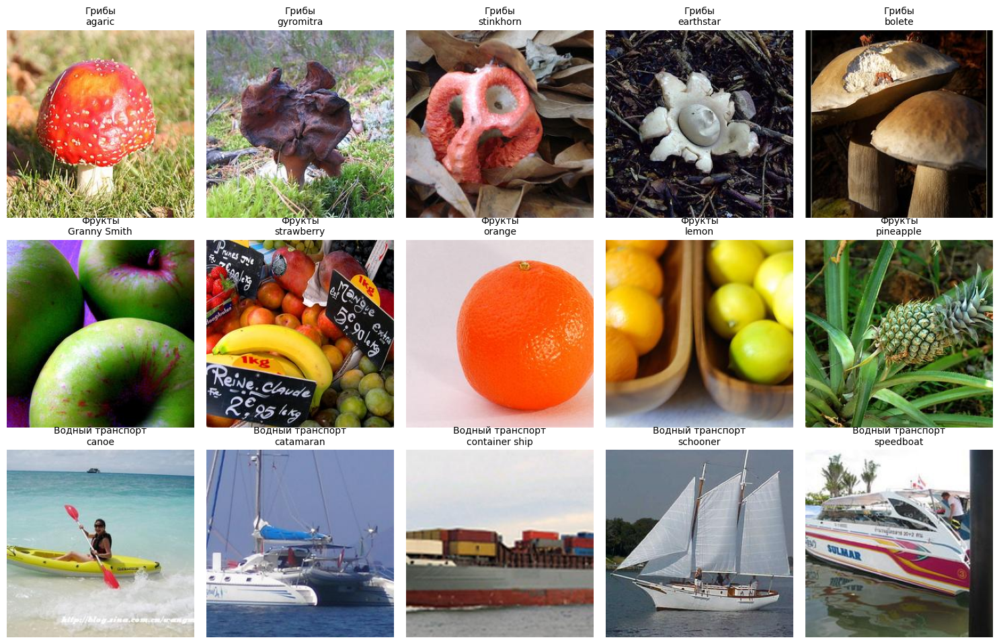

In [5]:
# Примеры картинок: строка — метакласс, по одной картинке каждого исходного класса
fig, axes = plt.subplots(NUM_META, 5, figsize=(15, 3.2 * NUM_META))
rng = random.Random(0)
for m, (meta, classes) in enumerate(META_CLASSES.items()):
    for j, fine in enumerate(classes):
        path = rng.choice([p for p, f in train_samples if f == fine])
        axes[m, j].imshow(Image.open(path))
        axes[m, j].set_title(f'{meta}\n{FINE_NAMES[fine]}', fontsize=10)
        axes[m, j].axis('off')
plt.tight_layout()
plt.show()

## 1.3. Препроцессинг и аугментации

- **Нормализация статистиками ImageNet** (`mean=[0.485, 0.456, 0.406]`, `std=[0.229, 0.224, 0.225]`) — обязательна: предобученная сеть обучалась именно на так нормированных входах.
- **Test/val:** центральный кроп 224×224 из картинки 256×256 — стандартный протокол оценки на ImageNet.
- **Train (только для fine-tuning):** случайный кроп с масштабом (как `RandomResizedCrop(224, scale=(0.5, 1))`), горизонтальное отражение и небольшое изменение яркости, контраста и насыщенности (как `ColorJitter(0.2, 0.2, 0.2)`). Вертикальное отражение не используем: перевёрнутые лодки и грибы в тесте не встречаются. Сильный цветовой сдвиг тоже не нужен: цвет — полезный признак (зелёное яблоко, оранжевый апельсин).
- Для fixed feature extractor признаки считаются один раз без аугментаций (см. 1.6).

**Как устроено для скорости.** У Colab всего 2 ядра CPU: если на каждой эпохе заново декодировать ~16 тыс. JPEG и делать аугментации на CPU, GPU большую часть времени простаивает (первый запуск — ~6 мин на эпоху). Поэтому:
1. все картинки один раз декодируются в память в один тензор `uint8` (они уже 256×256, ~3.5 ГБ RAM);
2. в обучение по батчам передаются сырые `uint8`-картинки, а аугментации выполняются **на GPU сразу для всего батча**, с отдельными случайными параметрами для каждой картинки: кроп с изменением масштаба — через `torchvision.ops.roi_align` (вырезает и масштабирует свою рамку для каждой картинки за один вызов), отражение и цветовые преобразования — поэлементными операциями;
3. модели работают в формате `channels_last` и mixed precision — так свёртки идут на тензорных ядрах T4.

  0%|          | 0/16575 [00:00<?, ?it/s]

  0%|          | 0/2925 [00:00<?, ?it/s]

  0%|          | 0/750 [00:00<?, ?it/s]

{'train': (16575, 3, 256, 256), 'val': (2925, 3, 256, 256), 'test': (750, 3, 256, 256)} 3.7 ГБ


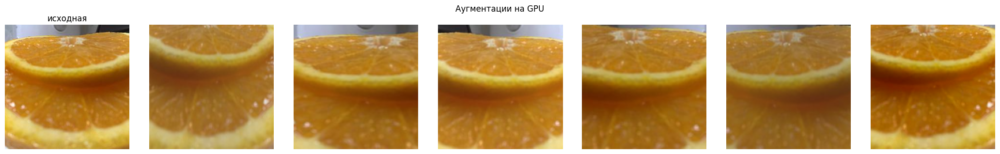

In [6]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
from torchvision.io import decode_image, read_file, ImageReadMode
from torchvision.ops import roi_align


def decode_split(samples):
    images = torch.stack([decode_image(read_file(path), mode=ImageReadMode.RGB) for path, _ in tqdm(samples, leave=False)])
    return images.pin_memory() if device.type == 'cuda' else images


splits = {'train': train_samples, 'val': val_samples, 'test': test_samples}
X_u8 = {split: decode_split(samples) for split, samples in splits.items()}
Y_meta = {split: torch.tensor([FINE_TO_META[f] for _, f in samples]) for split, samples in splits.items()}
print({k: tuple(v.shape) for k, v in X_u8.items()}, f'{sum(v.numel() for v in X_u8.values()) / 2 ** 30:.1f} ГБ')

y_val, y_test = Y_meta['val'].numpy(), Y_meta['test'].numpy()
fine_test = np.array([f for _, f in test_samples])

MEAN_T = torch.tensor(IMAGENET_MEAN, device=device).view(1, 3, 1, 1)
STD_T = torch.tensor(IMAGENET_STD, device=device).view(1, 3, 1, 1)
GRAY_W = torch.tensor([0.299, 0.587, 0.114], device=device).view(1, 3, 1, 1)


def normalize(x):
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=CHANNELS_LAST)


def gpu_eval_batch(xb):
    # центральный кроп 224×224 из 256×256 и нормализация
    return normalize(xb[:, :, 16:240, 16:240].float() / 255)


def gpu_train_batch(xb, out_size=224, scale=(0.5, 1.0), ratio=(3 / 4, 4 / 3), jitter=0.2):
    # аугментации всего батча на GPU, со своими случайными параметрами для каждой картинки
    b, _, h, w = xb.shape
    x = xb.float() / 255

    def rnd(lo, hi):
        return torch.empty(b, device=device).uniform_(lo, hi)

    # RandomResizedCrop: случайная площадь и пропорции рамки, затем масштабирование до 224×224
    area = rnd(*scale) * h * w
    aspect = torch.exp(rnd(np.log(ratio[0]), np.log(ratio[1])))
    cw, ch = torch.sqrt(area * aspect).clamp(max=w), torch.sqrt(area / aspect).clamp(max=h)
    x0, y0 = rnd(0, 1) * (w - cw), rnd(0, 1) * (h - ch)
    boxes = torch.stack([torch.arange(b, device=device, dtype=torch.float32), x0, y0, x0 + cw, y0 + ch], dim=1)
    x = roi_align(x, boxes, output_size=out_size, spatial_scale=1.0, sampling_ratio=2, aligned=True)
    # RandomHorizontalFlip
    flip = (torch.rand(b, device=device) < 0.5).view(b, 1, 1, 1)
    x = torch.where(flip, x.flip(3), x)
    # ColorJitter: яркость, контраст, насыщенность
    x = x * rnd(1 - jitter, 1 + jitter).view(b, 1, 1, 1)
    mean_gray = (x * GRAY_W).sum(1, keepdim=True).mean(dim=(2, 3), keepdim=True)
    x = (x - mean_gray) * rnd(1 - jitter, 1 + jitter).view(b, 1, 1, 1) + mean_gray
    gray = (x * GRAY_W).sum(1, keepdim=True)
    x = (x - gray) * rnd(1 - jitter, 1 + jitter).view(b, 1, 1, 1) + gray
    return normalize(x.clamp(0, 1))


def iterate_batches(split, batch_size, shuffle=False, drop_last=False):
    # батчи сырых uint8-картинок и меток метаклассов, сразу на GPU
    X, Y = X_u8[split], Y_meta[split]
    order = torch.randperm(len(X)) if shuffle else torch.arange(len(X))
    stop = len(X) - len(X) % batch_size if drop_last else len(X)
    for i in range(0, stop, batch_size):
        idx = order[i:i + batch_size]
        yield X[idx].to(device, non_blocking=True), Y[idx].to(device, non_blocking=True)


# Проверка аугментаций: одна и та же картинка 6 раз
xb = X_u8['train'][:1].repeat(6, 1, 1, 1).to(device)
aug = (gpu_train_batch(xb).float() * STD_T + MEAN_T).clamp(0, 1).cpu()
fig, axes = plt.subplots(1, 7, figsize=(21, 3.2))
axes[0].imshow(X_u8['train'][0].permute(1, 2, 0)); axes[0].set_title('исходная')
for ax, img in zip(axes[1:], aug):
    ax.imshow(img.permute(1, 2, 0))
for ax in axes:
    ax.axis('off')
plt.suptitle('Аугментации на GPU'); plt.tight_layout(); plt.show()

## 1.4. Модель и метрики

**Бэкбоны.** Основной — **ResNet50** с весами `IMAGENET1K_V2` (80.9% top-1 на ImageNet): хорошо работает на ImageNet, разобран на лекции, 25 млн параметров — быстро обучается на T4. Для сравнения — **EfficientNet-B0** (`IMAGENET1K_V1`, 77.7% top-1): в 5 раз меньше параметров (5.3 млн), полезно понять, нужен ли тяжёлый бэкбон для такой задачи.

У бэкбона убираем последний `Linear` на 1000 классов и ставим свою голову:
- **linear** — один `Linear(признаки → 3)`: логистическая регрессия на признаках;
- **mlp** — `Linear(признаки → 512) → BatchNorm1d → ReLU → Dropout(0.3) → Linear(512 → 3)`. Скрытый слой позволяет нелинейно комбинировать признаки; BatchNorm ускоряет обучение, Dropout — регуляризация, т.к. головы обучаются на ~16 тыс. примеров с 2048 признаками.

**Loss** — `CrossEntropyLoss`: стандарт для многоклассовой классификации, классы сбалансированы, весов не нужно.

**Оптимизатор** — `AdamW` (Adam с отделённым weight decay) и косинусное затухание lr: устойчиво работает без долгого подбора lr.

**Метрики.** Accuracy (метаклассы сбалансированы, поэтому она информативна), macro-F1 (среднее F1 по классам — заметит, если просел один метакласс), precision/recall по классам и матрица ошибок. Дополнительно смотрим, на каких исходных классах ImageNet модель ошибается.

In [7]:
BACKBONES = {
    'resnet50': (models.resnet50, models.ResNet50_Weights.IMAGENET1K_V2, 'fc'),
    'efficientnet_b0': (models.efficientnet_b0, models.EfficientNet_B0_Weights.IMAGENET1K_V1, 'classifier'),
    'resnet18': (models.resnet18, models.ResNet18_Weights.IMAGENET1K_V1, 'fc'),  # только для обучения с нуля
}
FE_BACKBONES = ['resnet50', 'efficientnet_b0']


def load_backbone(name, pretrained=True):
    """Сеть без последнего слоя классификации (по умолчанию с весами ImageNet) и размер её признаков."""
    builder, weights, head_attr = BACKBONES[name]
    net = builder(weights=weights if pretrained else None)
    head = getattr(net, head_attr)
    in_features = head.in_features if isinstance(head, nn.Linear) else head[-1].in_features
    setattr(net, head_attr, nn.Identity())
    return net, in_features


def make_head(in_features, kind='mlp', hidden=512, dropout=0.3):
    if kind == 'linear':
        return nn.Linear(in_features, NUM_META)
    return nn.Sequential(
        nn.Linear(in_features, hidden),
        nn.BatchNorm1d(hidden),
        nn.ReLU(inplace=True),
        nn.Dropout(dropout),
        nn.Linear(hidden, NUM_META),
    )


class MetaClassifier(nn.Module):
    def __init__(self, backbone_name, head_kind='mlp', pretrained=True):
        super().__init__()
        self.backbone, in_features = load_backbone(backbone_name, pretrained)
        self.head = make_head(in_features, head_kind)

    def forward(self, x):
        return self.head(self.backbone(x))


def classification_metrics(y_true, y_pred):
    return {'accuracy': accuracy_score(y_true, y_pred), 'macro_f1': f1_score(y_true, y_pred, average='macro')}


def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)

## 1.5. Эксперимент 0: предобученная сеть без обучения (baseline)

Наши метаклассы состоят из классов ImageNet, поэтому исходная ResNet50 уже умеет их распознавать. Берём её выход на 1000 классов, суммируем вероятности классов каждого метакласса и выбираем метакласс с наибольшей суммой. Это нижняя планка: всё, что мы обучаем дальше, должно быть не хуже.

In [8]:
@torch.no_grad()
def predict_logits(net, split, batch_size=256):
    net.eval()
    outputs = []
    for xb, _ in iterate_batches(split, batch_size):
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            outputs.append(net(gpu_eval_batch(xb)).float().cpu())
    return torch.cat(outputs)


imagenet_resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2).to(device, memory_format=CHANNELS_LAST)
members = [list(classes) for classes in META_CLASSES.values()]


def zero_shot(split):
    probs = predict_logits(imagenet_resnet, split).softmax(dim=1)
    meta_scores = torch.stack([probs[:, m].sum(dim=1) for m in members], dim=1)
    return meta_scores.argmax(dim=1).numpy(), probs


start = time.time()
zs_val_pred, _ = zero_shot('val')
zs_test_pred, zs_test_probs = zero_shot('test')

# Сводная таблица экспериментов и предсказания на test хранятся на Drive:
# после перезапуска уже выполненные эксперименты не пересчитываются
RESULTS_FILE = os.path.join(SAVE_DIR, 'task1_results' + ('_quick' if QUICK else '') + '.pt')
saved = torch.load(RESULTS_FILE, weights_only=False) if os.path.exists(RESULTS_FILE) else {}
results = saved.get('results', [])        # сводная таблица всех экспериментов
test_preds = saved.get('test_preds', {})  # предсказания на test для анализа ошибок
ft_histories = saved.get('ft_histories', {})


def save_results():
    torch.save({'results': results, 'test_preds': test_preds, 'ft_histories': ft_histories}, RESULTS_FILE)


def add_result(name, mode, trainable, seconds, val_pred, test_pred):
    m_val, m_test = classification_metrics(y_val, val_pred), classification_metrics(y_test, test_pred)
    results[:] = [r for r in results if r['эксперимент'] != name]
    results.append({'эксперимент': name, 'режим': mode, 'обучаемых параметров': trainable, 'время, с': round(seconds),
                    'val acc': m_val['accuracy'], 'val macro-F1': m_val['macro_f1'],
                    'test acc': m_test['accuracy'], 'test macro-F1': m_test['macro_f1']})
    test_preds[name] = test_pred
    save_results()
    return m_val, m_test


add_result('ResNet50 без обучения (сумма вероятностей ImageNet)', 'zero-shot', 0, time.time() - start,
           zs_val_pred, zs_test_pred)

top1 = zs_test_probs.argmax(dim=1).numpy()
print(f'Top-1 класс ImageNet вне наших 15 классов: {np.mean(~np.isin(top1, WANTED)):.1%} тестовых картинок')
display(pd.DataFrame(results))
del imagenet_resnet

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 139MB/s]


Top-1 класс ImageNet вне наших 15 классов: 10.3% тестовых картинок


,эксперимент,режим,обучаемых параметров,"время, с",val acc,val macro-F1,test acc,test macro-F1
0,ResNet50 без обучения (сумма вероятностей Imag...,zero-shot,0,11,0.998632,0.998632,0.998667,0.998667


## 1.6. Fixed feature extractor

Замораживаем все веса бэкбона и обучаем только голову. Раз бэкбон не меняется и аугментаций нет, признаки каждой картинки одинаковы на всех эпохах — считаем их **один раз** и дальше обучаем голову на готовых векторах (2048 чисел для ResNet50, 1280 для EfficientNet-B0). Это даёт обучение головы за секунды и позволяет сравнить много вариантов.

Сравниваем 2 бэкбона × 2 головы. Лучшую эпоху выбираем по accuracy на val.

In [9]:
features, extract_seconds = {}, {}
for name in FE_BACKBONES:
    backbone, _ = load_backbone(name)
    backbone.to(device, memory_format=CHANNELS_LAST)
    start = time.time()
    features[name] = {split: predict_logits(backbone, split) for split in ['train', 'val', 'test']}
    extract_seconds[name] = time.time() - start
    print(f"{name}: признаки {tuple(features[name]['train'].shape)}, {extract_seconds[name]:.0f} с, "
          f'параметров бэкбона {count_params(backbone):,}')
    del backbone

y_train = np.array([FINE_TO_META[f] for _, f in train_samples])
fine_train = np.array([f for _, f in train_samples])

resnet50: признаки (16575, 2048), 27 с, параметров бэкбона 23,508,032
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 154MB/s]


efficientnet_b0: признаки (16575, 1280), 37 с, параметров бэкбона 4,007,548


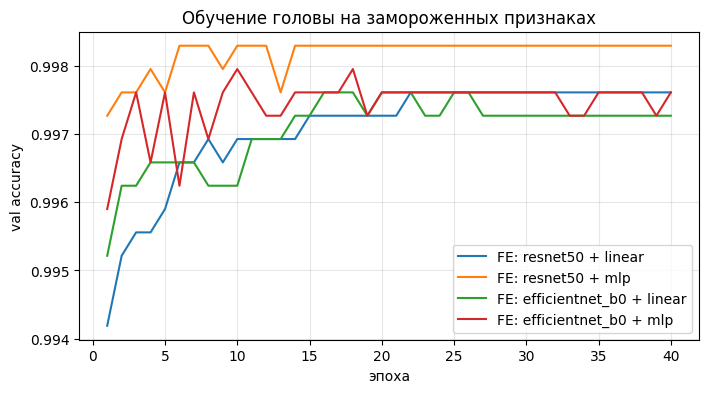

,эксперимент,режим,обучаемых параметров,"время, с",val acc,val macro-F1,test acc,test macro-F1
0,ResNet50 без обучения (сумма вероятностей ImageNet),zero-shot,0,11,0.9986,0.9986,0.9987,0.9987
1,FE: resnet50 + linear,fixed feature extractor,6147,37,0.9976,0.9976,1.0000,1.0000
2,FE: resnet50 + mlp,fixed feature extractor,1051651,40,0.9983,0.9983,0.9987,0.9987
3,FE: efficientnet_b0 + linear,fixed feature extractor,3843,48,0.9976,0.9976,0.9973,0.9973
4,FE: efficientnet_b0 + mlp,fixed feature extractor,658435,50,0.9979,0.9979,0.9947,0.9947


In [10]:
def train_head(backbone_name, head_kind, train_idx=None, epochs=None, lr=1e-3, weight_decay=1e-4, batch_size=256):
    set_seed(42)
    epochs = epochs or (5 if QUICK else 40)
    X, y = features[backbone_name]['train'], torch.tensor(y_train)
    if train_idx is not None:
        X, y = X[train_idx], y[train_idx]
    head = make_head(X.shape[1], head_kind).to(device)
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True, drop_last=len(y) > batch_size)
    optimizer = torch.optim.AdamW(head.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    X_val = features[backbone_name]['val'].to(device)

    best_acc, best_state, history = -1.0, None, []
    for epoch in range(epochs):
        head.train()
        for xb, yb in loader:
            loss = nn.functional.cross_entropy(head(xb.to(device)), yb.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
        head.eval()
        with torch.no_grad():
            val_acc = accuracy_score(y_val, head(X_val).argmax(1).cpu().numpy())
        history.append(val_acc)
        if val_acc > best_acc:
            best_acc, best_state = val_acc, copy.deepcopy(head.state_dict())
    head.load_state_dict(best_state)
    head.eval()
    return head, history


@torch.no_grad()
def head_predict(head, backbone_name, split):
    return head(features[backbone_name][split].to(device)).argmax(1).cpu().numpy()


fe_histories = {}
for backbone_name in FE_BACKBONES:
    for head_kind in ['linear', 'mlp']:
        start = time.time()
        head, history = train_head(backbone_name, head_kind)
        name = f'FE: {backbone_name} + {head_kind}'
        fe_histories[name] = history
        add_result(name, 'fixed feature extractor', count_params(head),
                   time.time() - start + extract_seconds[backbone_name],
                   head_predict(head, backbone_name, 'val'), head_predict(head, backbone_name, 'test'))

plt.figure(figsize=(8, 4))
for name, history in fe_histories.items():
    plt.plot(range(1, len(history) + 1), history, label=name)
plt.xlabel('эпоха'); plt.ylabel('val accuracy'); plt.title('Обучение головы на замороженных признаках')
plt.legend(); plt.grid(alpha=0.3); plt.show()

display(pd.DataFrame(results).style.format({c: '{:.4f}' for c in ['val acc', 'val macro-F1', 'test acc', 'test macro-F1']}))

### Сколько данных нужно голове

Предобученные признаки уже хорошо разделяют метаклассы, поэтому интересно, сколько размеченных картинок на самом деле нужно. Обучаем MLP-голову на ResNet50-признаках, оставляя `n` картинок на каждый исходный класс (то есть `5n` на метакласс), и смотрим accuracy на val.

,картинок на класс,всего в train,val acc
0,2,30,0.990769
1,5,75,0.994188
2,10,150,0.993846
3,25,375,0.994530
4,50,750,0.996239
5,100,1500,0.995556
6,250,3750,0.997265
7,500,7500,0.997607
8,все,16575,0.998291


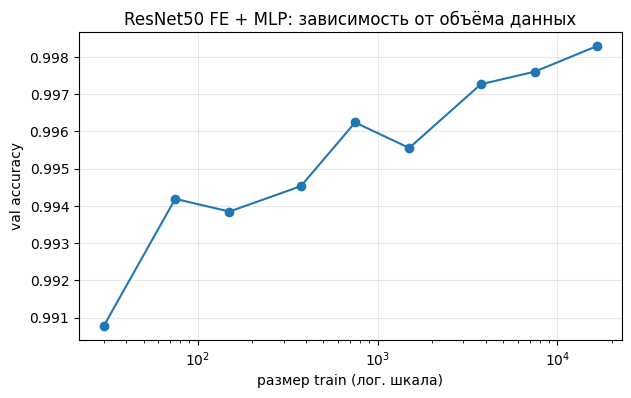

In [11]:
def per_class_subset(n, seed=0):
    rng = np.random.default_rng(seed)
    idx = [rng.choice(np.where(fine_train == f)[0], size=min(n, (fine_train == f).sum()), replace=False) for f in WANTED]
    return np.concatenate(idx)


sizes = [5, 20] if QUICK else [2, 5, 10, 25, 50, 100, 250, 500, None]
efficiency = []
for n in sizes:
    idx = None if n is None else per_class_subset(n)
    head, _ = train_head('resnet50', 'mlp', train_idx=idx, epochs=None if n is None else (5 if QUICK else 100))
    n_used = len(y_train) if idx is None else len(idx)
    efficiency.append({'картинок на класс': 'все' if n is None else n, 'всего в train': n_used,
                       'val acc': accuracy_score(y_val, head_predict(head, 'resnet50', 'val'))})

efficiency = pd.DataFrame(efficiency)
display(efficiency)
plt.figure(figsize=(7, 4))
plt.plot(efficiency['всего в train'], efficiency['val acc'], marker='o')
plt.xscale('log'); plt.xlabel('размер train (лог. шкала)'); plt.ylabel('val accuracy')
plt.title('ResNet50 FE + MLP: зависимость от объёма данных'); plt.grid(alpha=0.3); plt.show()

## 1.7. Fine-tuning

Теперь обучаем всю сеть целиком, начиная с весов ImageNet. Отличия от fixed feature extractor:
- **аугментации** на train (раздел 1.3) — признаки теперь меняются, и сеть может переобучиться на ~16 тыс. картинок;
- **разный learning rate**: голова со случайными весами учится с `lr=1e-3`, а бэкбон — в 10 раз медленнее (`1e-4`), чтобы не разрушить хорошие предобученные признаки в первые шаги;
- **OneCycle** (разогрев 10% шагов, затем косинусное затухание) — короткий разогрев защищает предобученные веса, пока голова ещё случайная;
- **mixed precision**, `channels_last` и аугментации на GPU — для скорости (батч 128).

Обучаем 5 эпох (больше не нужно: сеть стартует с хороших признаков). Лучшую эпоху выбираем по val. После каждой эпохи чекпоинт сохраняется на Google Drive: если колаб отключится, после перезапуска обучение продолжится с последней эпохи, а уже законченные эксперименты не пересчитываются.

**Контрольный эксперимент — обучение с нуля.** Метаклассы состоят из классов ImageNet, поэтому предобученная сеть их уже знает, и все варианты переноса обучения дают почти 100%. Чтобы увидеть, что именно даёт перенос, обучаем ту же схему со случайной инициализацией весов. Берём ResNet18 (11 млн параметров — меньше, чем ResNet50, ей легче обучиться с нуля на ~16 тыс. картинок), один lr `1e-3` для всей сети и 12 эпох.

In [12]:
def finetune(backbone_name, head_kind='mlp', pretrained=True, epochs=None, lr_backbone=1e-4, lr_head=1e-3,
             weight_decay=1e-4, checkpoint=None):
    set_seed(42)
    epochs = epochs or (1 if QUICK else 5)
    model = MetaClassifier(backbone_name, head_kind, pretrained).to(device, memory_format=CHANNELS_LAST)
    batch_size = 32 if QUICK else 128  # в быстром режиме — меньше, чтобы проверка шла и без мощной GPU
    steps_per_epoch = len(train_samples) // batch_size
    optimizer = torch.optim.AdamW([
        {'params': model.backbone.parameters(), 'lr': lr_backbone},
        {'params': model.head.parameters(), 'lr': lr_head},
    ], weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[lr_backbone, lr_head], total_steps=epochs * steps_per_epoch, pct_start=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    history, best_acc, best_state, first_epoch = [], -1.0, None, 1
    if checkpoint and os.path.exists(checkpoint):  # продолжаем прерванное обучение
        ckpt = torch.load(checkpoint, map_location=device, weights_only=False)
        model.load_state_dict(ckpt['model']); optimizer.load_state_dict(ckpt['optimizer'])
        scheduler.load_state_dict(ckpt['scheduler']); scaler.load_state_dict(ckpt['scaler'])
        history, best_acc, best_state = ckpt['history'], ckpt['best_acc'], ckpt['best_state']
        first_epoch = ckpt['epoch'] + 1
        print(f'Продолжаем с эпохи {first_epoch} (чекпоинт {checkpoint})')

    for epoch in range(first_epoch, epochs + 1):
        start = time.time()
        model.train()
        running_loss, correct, seen = 0.0, 0, 0
        for xb, y in tqdm(iterate_batches('train', batch_size, shuffle=True, drop_last=True), total=steps_per_epoch,
                          desc=f'{backbone_name} epoch {epoch}/{epochs}', leave=False):
            x = gpu_train_batch(xb)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logits = model(x)
                loss = nn.functional.cross_entropy(logits, y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running_loss += loss.item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            seen += len(y)

        val_pred = predict_logits(model, 'val').argmax(1).numpy()
        m_val = classification_metrics(y_val, val_pred)
        history.append({'epoch': epoch, 'train loss': running_loss / seen, 'train acc': correct / seen,
                        'val acc': m_val['accuracy'], 'val macro-F1': m_val['macro_f1'], 'sec': time.time() - start})
        print(f"epoch {epoch}: train loss {history[-1]['train loss']:.4f}, train acc {history[-1]['train acc']:.4f}, "
              f"val acc {m_val['accuracy']:.4f}, val F1 {m_val['macro_f1']:.4f}, {history[-1]['sec']:.0f} с")
        if m_val['accuracy'] > best_acc:
            best_acc, best_state = m_val['accuracy'], {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if checkpoint:
            torch.save({'epoch': epoch, 'model': model.state_dict(), 'optimizer': optimizer.state_dict(),
                        'scheduler': scheduler.state_dict(), 'scaler': scaler.state_dict(),
                        'history': history, 'best_acc': best_acc, 'best_state': best_state}, checkpoint)

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)


ft_runs = [
    ('FT: resnet50 + mlp', 'fine-tuning', dict(backbone_name='resnet50')),
    ('FT: efficientnet_b0 + mlp', 'fine-tuning', dict(backbone_name='efficientnet_b0')),
    ('С нуля: resnet18 + mlp', 'обучение с нуля',
     dict(backbone_name='resnet18', pretrained=False, epochs=1 if QUICK else 12, lr_backbone=1e-3)),
]
for name, mode, kwargs in ft_runs:
    if name in test_preds:
        print(f'{name}: уже посчитан, берём результат с Drive')
        continue
    checkpoint = os.path.join(SAVE_DIR, 'ckpt_' + name.split(':')[0].replace(' ', '_') + '_' + kwargs['backbone_name']
                              + ('_quick' if QUICK else '') + '.pt')
    start = time.time()
    model, history = finetune(checkpoint=checkpoint, **kwargs)
    ft_histories[name] = history
    add_result(name, mode, count_params(model, trainable_only=True), time.time() - start,
               predict_logits(model, 'val').argmax(1).numpy(), predict_logits(model, 'test').argmax(1).numpy())
    del model
    if device.type == 'cuda':
        torch.cuda.empty_cache()

resnet50 epoch 1/5:   0%|          | 0/129 [00:00<?, ?it/s]

epoch 1: train loss 0.1117, train acc 0.9639, val acc 0.9956, val F1 0.9956, 66 с


resnet50 epoch 2/5:   0%|          | 0/129 [00:00<?, ?it/s]

epoch 2: train loss 0.0114, train acc 0.9972, val acc 0.9959, val F1 0.9959, 63 с


resnet50 epoch 3/5:   0%|          | 0/129 [00:00<?, ?it/s]

...

epoch 10: train loss 0.1268, train acc 0.9542, val acc 0.9439, val F1 0.9437, 27 с


resnet18 epoch 11/12:   0%|          | 0/129 [00:00<?, ?it/s]

epoch 11: train loss 0.1139, train acc 0.9577, val acc 0.9528, val F1 0.9527, 28 с


resnet18 epoch 12/12:   0%|          | 0/129 [00:00<?, ?it/s]

epoch 12: train loss 0.1084, train acc 0.9611, val acc 0.9532, val F1 0.9531, 27 с


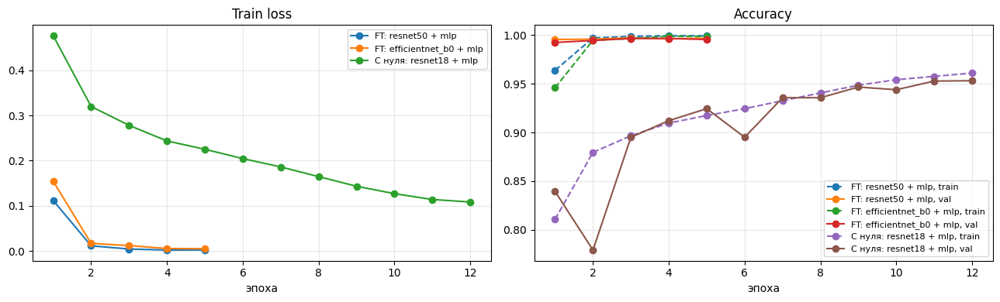

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, history in ft_histories.items():
    axes[0].plot(history['epoch'], history['train loss'], marker='o', label=name)
    axes[1].plot(history['epoch'], history['train acc'], marker='o', ls='--', label=f'{name}, train')
    axes[1].plot(history['epoch'], history['val acc'], marker='o', label=f'{name}, val')
axes[0].set_title('Train loss'); axes[1].set_title('Accuracy')
for ax in axes:
    ax.set_xlabel('эпоха'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 1.8. Сравнение экспериментов и итоговая модель

Итоговую модель выбираем среди обученных вариантов **по val macro-F1**, при равенстве — по меньшему числу обучаемых параметров (проще и дешевле). Test используется только для финальной оценки. Baseline без обучения в выборе не участвует: по заданию нужна обученная голова на 3 метакласса.

In [14]:
summary = pd.DataFrame(results)
display(summary.style.format({c: '{:.4f}' for c in ['val acc', 'val macro-F1', 'test acc', 'test macro-F1']})
        .format({'обучаемых параметров': '{:,}'}))

trained = summary[summary['режим'] != 'zero-shot']
best_row = trained.sort_values(['val macro-F1', 'обучаемых параметров'], ascending=[False, True]).iloc[0]
best_name = best_row['эксперимент']
best_pred = test_preds[best_name]
print(f'Итоговая модель: {best_name}')
print(f"test accuracy = {best_row['test acc']:.4f}, test macro-F1 = {best_row['test macro-F1']:.4f}\n")
print(classification_report(y_test, best_pred, target_names=META_NAMES, digits=4))

,эксперимент,режим,обучаемых параметров,"время, с",val acc,val macro-F1,test acc,test macro-F1
0,ResNet50 без обучения (сумма вероятностей ImageNet),zero-shot,0,11,0.998632,0.998632,0.998667,0.998667
1,FE: resnet50 + linear,fixed feature extractor,"6,147",37,0.997607,0.997607,1.000000,1.000000
2,FE: resnet50 + mlp,fixed feature extractor,"1,051,651",40,0.998291,0.998291,0.998667,0.998667
3,FE: efficientnet_b0 + linear,fixed feature extractor,"3,843",48,0.997607,0.997607,0.997333,0.997333
4,FE: efficientnet_b0 + mlp,fixed feature extractor,"658,435",50,0.997949,0.997949,0.994667,0.994667
5,FT: resnet50 + mlp,fine-tuning,"24,559,683",369,0.997265,0.997265,0.998667,0.998667
6,FT: efficientnet_b0 + mlp,fine-tuning,"4,665,983",267,0.996581,0.996581,0.998667,0.998667
7,С нуля: resnet18 + mlp,обучение с нуля,"11,441,731",418,0.953162,0.953095,0.964000,0.963875


Итоговая модель: FE: resnet50 + mlp
test accuracy = 0.9987, test macro-F1 = 0.9987

                  precision    recall  f1-score   support

           Грибы     1.0000    0.9960    0.9980       250
          Фрукты     0.9960    1.0000    0.9980       250
Водный транспорт     1.0000    1.0000    1.0000       250

        accuracy                         0.9987       750
       macro avg     0.9987    0.9987    0.9987       750
    weighted avg     0.9987    0.9987    0.9987       750



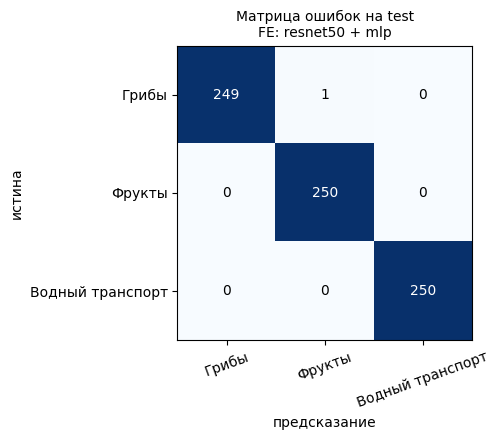

,класс,метакласс,accuracy,ошибки → куда
10,agaric,Грибы,0.98,Фрукты: 1
0,canoe,Водный транспорт,1.00,
2,container ship,Водный транспорт,1.00,
1,catamaran,Водный транспорт,1.00,
4,speedboat,Водный транспорт,1.00,
5,Granny Smith,Фрукты,1.00,
6,strawberry,Фрукты,1.00,
3,schooner,Водный транспорт,1.00,
7,orange,Фрукты,1.00,
8,lemon,Фрукты,1.00,


In [15]:
cm = confusion_matrix(y_test, best_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_META), META_NAMES, rotation=20); ax.set_yticks(range(NUM_META), META_NAMES)
ax.set_xlabel('предсказание'); ax.set_ylabel('истина'); ax.set_title(f'Матрица ошибок на test\n{best_name}', fontsize=10)
for i in range(NUM_META):
    for j in range(NUM_META):
        ax.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.tight_layout(); plt.show()

# На каких исходных классах ImageNet ошибается итоговая модель
rows = []
for fine in WANTED:
    sel = fine_test == fine
    wrong = Counter(META_NAMES[p] for p in best_pred[sel] if p != FINE_TO_META[fine])
    rows.append({'класс': FINE_NAMES[fine], 'метакласс': META_NAMES[FINE_TO_META[fine]],
                 'accuracy': (best_pred[sel] == y_test[sel]).mean(),
                 'ошибки → куда': ', '.join(f'{k}: {v}' for k, v in wrong.most_common())})
display(pd.DataFrame(rows).sort_values('accuracy'))

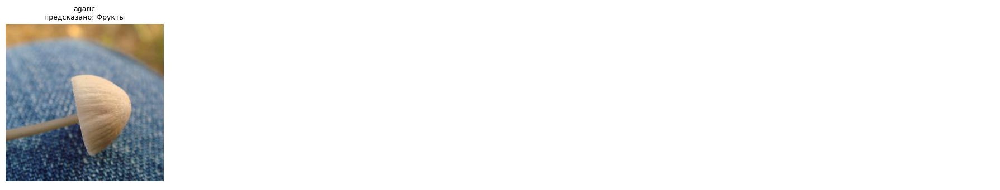

Ошибок: 1 из 750


In [16]:
# Картинки, на которых итоговая модель ошиблась
wrong_idx = np.where(best_pred != y_test)[0]
show = wrong_idx[:12]
if len(show):
    cols = 6
    rows_n = int(np.ceil(len(show) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(3 * cols, 3.3 * rows_n), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, show):
        path, fine = test_samples[i]
        ax.imshow(Image.open(path))
        ax.set_title(f'{FINE_NAMES[fine]}\nпредсказано: {META_NAMES[best_pred[i]]}', fontsize=9)
    plt.tight_layout(); plt.show()
print(f'Ошибок: {len(wrong_idx)} из {len(y_test)}')

## 1.9. Выводы по заданию 1

| Эксперимент | Режим | Обучаемых параметров | Время, с | val acc | test acc | Ошибок на test (из 750) |
|---|---|---:|---:|---:|---:|---:|
| ResNet50 без обучения | zero-shot | 0 | 11 | 0.9986 | 0.9987 | 1 |
| ResNet50 + linear | fixed feature extractor | 6 147 | 37 | 0.9976 | **1.0000** | 0 |
| **ResNet50 + MLP** (итоговая) | fixed feature extractor | 1 051 651 | 40 | **0.9983** | 0.9987 | 1 |
| EfficientNet-B0 + linear | fixed feature extractor | 3 843 | 48 | 0.9976 | 0.9973 | 2 |
| EfficientNet-B0 + MLP | fixed feature extractor | 658 435 | 50 | 0.9979 | 0.9947 | 4 |
| ResNet50 + MLP | fine-tuning, 5 эпох | 24 559 683 | 369 | 0.9973 | 0.9987 | 1 |
| EfficientNet-B0 + MLP | fine-tuning, 5 эпох | 4 665 983 | 267 | 0.9966 | 0.9987 | 1 |
| ResNet18 + MLP | обучение с нуля, 12 эпох | 11 441 731 | 418 | 0.9532 | 0.9640 | 27 |

- **Baseline без обучения.** ResNet50, обученная на ImageNet, даёт **0.9987** accuracy на test (1 ошибка из 750), если просто сложить вероятности классов внутри метакласса. Это ожидаемо: метаклассы собраны из классов ImageNet, и сеть уже различает именно эти объекты. Только у 10.3% тестовых картинок самый вероятный класс ImageNet лежит вне наших 15 классов, и даже тогда сумма вероятностей обычно указывает на правильный метакласс.
- **Fixed feature extractor.** Все 4 варианта дают 0.995–1.000 на test. Голова обучается за секунды (40–50 с вместе с однократным подсчётом признаков). Разница между вариантами — от 0 до 4 ошибок из 750, то есть на уровне шума:
  - MLP-голова против линейной: на val 0.9983 против 0.9976 (2 картинки из 2925), на test наоборот — 1 ошибка против 0. Признаки ResNet50 разделяют метаклассы почти линейно, поэтому скрытый слой ничего существенного не добавляет.
  - EfficientNet-B0 против ResNet50: чуть хуже (2–4 ошибки против 0–1), зато бэкбон в 6 раз меньше (4.0 млн параметров против 23.5 млн).
- **Объём данных.** Уже при **2 картинках на исходный класс** (30 картинок в train!) val accuracy = **0.991**, при 5 — 0.994, при 50 — 0.996, при всех 16 575 — 0.998. Предобученные признаки почти линейно разделяют метаклассы, поэтому много размеченных данных не нужно: рост от 30 до 16 575 картинок даёт меньше 1%.
- **Fine-tuning.** Даёт 0.9987 на test (1 ошибка) у обоих бэкбонов — столько же, сколько FE + MLP, но обучение заняло **4.5–6 мин** против **~40 с** у FE, а обучаемых параметров у ResNet50 в 23 раза больше. Train accuracy уже со 2-й эпохи ≈ 0.997–0.999, val не растёт — сеть сразу выходит на потолок. Когда новая задача близка к ImageNet, достаточно замороженного бэкбона; fine-tuning оправдан, когда домен заметно отличается (как сегментация в задании 2).
- **Обучение с нуля** (ResNet18, 12 эпох) — только **0.964** на test (27 ошибок против 0–1 у переноса обучения), хотя обучалось дольше всех (7 мин). Val accuracy всё ещё растёт к 12-й эпохе (0.84 → 0.95), то есть сеть не сошлась. Разница — это вклад признаков, выученных на 1.28 млн картинок ImageNet: на ~16 тыс. наших картинок такие признаки за разумное время с нуля не выучить.
- **Итоговая модель:** **ResNet50 (замороженный) + MLP-голова** — лучшая по val macro-F1 (0.9983). На test: accuracy **0.9987**, macro-F1 **0.9987**; «Водный транспорт» распознаётся без ошибок, у «Грибов» recall 0.996, у «Фруктов» precision 0.996.
- **Ошибки.** Единственная ошибка итоговой модели — гриб **agaric**, распознанный как «Фрукты»: маленькая гладкая бежевая шляпка на джинсовой ткани, крупным планом, без леса, травы и листвы вокруг. По форме и фактуре она похожа на фрукт или орех, а привычного «грибного» контекста в кадре нет.
- **Почему почти все варианты дают ~99–100%.** Метаклассы собраны из классов ImageNet, и предобученный бэкбон уже различает именно эти объекты. Поэтому варианты переноса обучения имеет смысл сравнивать по числу ошибок в штуках, а не по accuracy: на 750 тестовых картинках 1 ошибка = 0.13%. Реальную разницу между подходами показывает только обучение с нуля.

# Задание 2. Семантическая сегментация воды на фото наводнений: U-Net и классические методы

**Датасет:** [Flood Area Segmentation](https://www.kaggle.com/datasets/faizalkarim/flood-area-segmentation) (Kaggle, лицензия CC0) — 290 фотографий районов наводнений и маски области воды, размеченные вручную в Label Studio. Фото разного размера (от ~300 до ~4000 px по стороне), разные ракурсы: съёмка с земли, с дронов, с вертолёта.

Задача — для каждого пикселя определить, вода это или нет (2 класса: вода / фон).

## 2.1. Загрузка данных

Датасет публичный, скачиваем его напрямую через Kaggle API. Если Kaggle вернёт ошибку доступа, нужно добавить в секреты Colab `KAGGLE_USERNAME` и `KAGGLE_KEY` (Kaggle → Settings → API → Create New Token) и использовать закомментированный вариант через `kagglehub`.

In [17]:
# Задание 2 можно запускать без задания 1: повторяем нужные общие определения
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]


def count_params(module, trainable_only=False):
    return sum(p.numel() for p in module.parameters() if p.requires_grad or not trainable_only)


FLOOD_URL = 'https://www.kaggle.com/api/v1/datasets/download/faizalkarim/flood-area-segmentation'
FLOOD_ZIP = os.path.join(DATA_DIR, 'flood.zip')
FLOOD_DIR = os.path.join(DATA_DIR, 'flood')

if not os.path.isdir(FLOOD_DIR):
    if not os.path.exists(FLOOD_ZIP):
        urllib.request.urlretrieve(FLOOD_URL, FLOOD_ZIP)
        # Вариант с авторизацией:
        # import kagglehub; FLOOD_DIR = kagglehub.dataset_download('faizalkarim/flood-area-segmentation')
    with zipfile.ZipFile(FLOOD_ZIP) as zf:
        zf.extractall(FLOOD_DIR)

meta = pd.read_csv(os.path.join(FLOOD_DIR, 'metadata.csv'))
print('Пар картинка-маска:', len(meta))
sizes = Counter(Image.open(os.path.join(FLOOD_DIR, 'Image', f)).size for f in meta['Image'])
print(f'Разных размеров: {len(sizes)}; самые частые (W, H):', sizes.most_common(4))

Пар картинка-маска: 290
Разных размеров: 201; самые частые (W, H): [((1024, 682), 7), ((1200, 800), 5), ((1280, 720), 5), ((1200, 900), 4)]


**Препроцессинг.** Все фото и маски приводим к **256×256**:
- размеры фото разные, а для батча нужен один;
- 256 делится на 32 — это нужно U-Net с 5 понижениями разрешения (вариант с ResNet-энкодером);
- 290 картинок 256×256 занимают в памяти ~60 МБ.

Фото в среднем имеют пропорции 3:2, при сжатии в квадрат они немного искажаются по горизонтали. Для сегментации воды это некритично, а все методы сравниваются на одних и тех же 256×256.

Маски хранятся в оттенках серого, на границах есть промежуточные значения. Масштабируем маску билинейно и бинаризуем порогом 127. Несколько фото с прозрачностью или палитрой приводим к RGB. У 7 пар размер маски не совпадает с размером фото — после приведения к 256×256 это неважно.

In [18]:
IMG_SIZE = 256


def load_flood(row):
    image = Image.open(os.path.join(FLOOD_DIR, 'Image', row['Image'])).convert('RGB')
    mask = Image.open(os.path.join(FLOOD_DIR, 'Mask', row['Mask'])).convert('L')
    image = np.array(image.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR))
    mask = (np.array(mask.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)) > 127).astype(np.uint8)
    return image, mask


loaded = [load_flood(row) for _, row in tqdm(meta.iterrows(), total=len(meta))]
images = np.stack([x[0] for x in loaded])
masks = np.stack([x[1] for x in loaded])
del loaded

idx_all = np.arange(len(images))
idx_train, idx_rest = train_test_split(idx_all, test_size=0.3, random_state=42)
idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, random_state=42)
print(f'train {len(idx_train)}, val {len(idx_val)}, test {len(idx_test)}')

water_share = masks.reshape(len(masks), -1).mean(1)
print(f'Доля пикселей воды: в среднем {water_share.mean():.1%}, медиана {np.median(water_share):.1%}, '
      f'от {water_share.min():.1%} до {water_share.max():.1%}')

  0%|          | 0/290 [00:00<?, ?it/s]

train 203, val 43, test 44
Доля пикселей воды: в среднем 40.7%, медиана 37.3%, от 4.3% до 87.9%


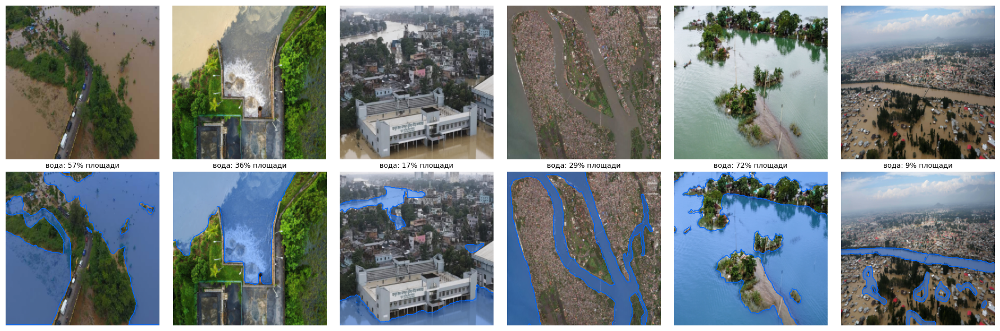

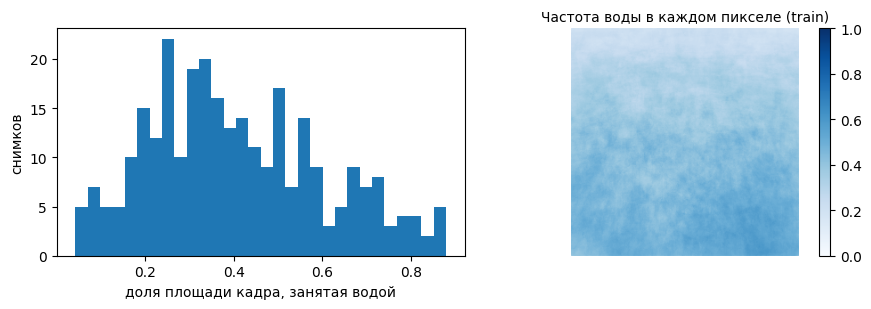

In [19]:
def overlay(ax, image, mask, color=(0, 0.4, 1), title=None):
    ax.imshow(image)
    rgba = np.zeros((*mask.shape, 4))
    rgba[mask.astype(bool)] = (*color, 0.4)
    ax.imshow(rgba)
    ax.contour(mask, levels=[0.5], colors=[color], linewidths=1)
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(2, 6, figsize=(18, 6))
for k, i in enumerate(np.random.default_rng(1).choice(idx_train, 6, replace=False)):
    axes[0, k].imshow(images[i]); axes[0, k].axis('off')
    overlay(axes[1, k], images[i], masks[i], title=f'вода: {water_share[i]:.0%} площади')
plt.tight_layout(); plt.show()

# Где в кадре обычно вода: средняя маска по train
plt.figure(figsize=(9, 3.2))
plt.subplot(1, 2, 1)
plt.hist(water_share, bins=30); plt.xlabel('доля площади кадра, занятая водой'); plt.ylabel('снимков')
plt.subplot(1, 2, 2)
plt.imshow(masks[idx_train].mean(0), cmap='Blues', vmin=0, vmax=1); plt.colorbar(); plt.axis('off')
plt.title('Частота воды в каждом пикселе (train)', fontsize=10)
plt.tight_layout(); plt.show()

**Разбиение:** train 203 / val 43 / test 44 (70/15/15, seed 42). На val выбираем лучшую эпоху, на test сравниваем все методы.

Вода занимает в среднем ~40% кадра, так что классы не сильно несбалансированы. Вода чаще находится в нижней части кадра (небо и здания сверху) — это видно по средней маске. Эту закономерность используют автоматические классические методы ниже.

## 2.2. Аугментации

Train-выборка очень маленькая (203 фото), поэтому аугментации обязательны. Геометрические преобразования применяются **одинаково к картинке и маске** (маска обёрнута в `tv_tensors.Mask`, её `torchvision.transforms.v2` интерполирует ближайшим соседом), цветовые — только к картинке:
- **горизонтальное отражение** — естественно для фото;
- **поворот до 10°** — наклон камеры;
- **RandomResizedCrop(scale 0.5–1)** — разный масштаб и кадрирование;
- **ColorJitter** — разное освещение, мутность и цвет воды (от коричневой до серо-голубой).

**Вертикальное отражение не используем**: на фото вода внизу, небо вверху, а сеть может использовать это как подсказку. Перевёрнутых фото в тесте не будет.

Нормализация — статистиками ImageNet: они нужны варианту с предобученным энкодером, и для единообразия так же нормализуем вход U-Net, обучаемой с нуля.

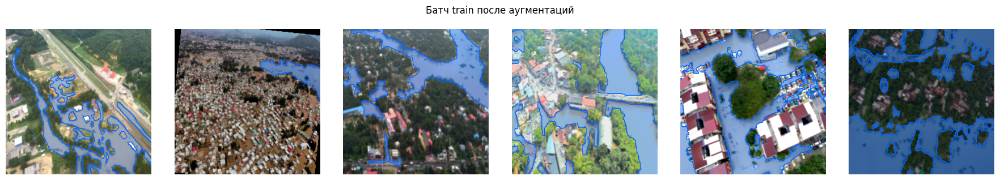

In [20]:
seg_train_tf = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomApply([v2.RandomRotation(10)], p=0.3),
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0), ratio=(0.75, 1.33), antialias=True),
    v2.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.25, hue=0.03),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
seg_eval_tf = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class FloodDataset(Dataset):
    def __init__(self, indices, transform):
        self.indices = indices
        self.transform = transform

    def __getitem__(self, k):
        i = self.indices[k]
        image = tv_tensors.Image(torch.from_numpy(images[i]).permute(2, 0, 1))
        mask = tv_tensors.Mask(torch.from_numpy(masks[i])[None])
        image, mask = self.transform(image, mask)
        return image, mask.float()

    def __len__(self):
        return len(self.indices)


seg_train_loader = DataLoader(FloodDataset(idx_train, seg_train_tf), batch_size=8, shuffle=True,
                              num_workers=NUM_WORKERS, drop_last=True, persistent_workers=NUM_WORKERS > 0)
seg_val_loader = DataLoader(FloodDataset(idx_val, seg_eval_tf), batch_size=32, shuffle=False)
seg_test_loader = DataLoader(FloodDataset(idx_test, seg_eval_tf), batch_size=32, shuffle=False)

# Проверка: после аугментаций маска должна совпадать с водой на картинке
xb, yb = next(iter(seg_train_loader))
mean_t, std_t = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 6, figsize=(18, 3.2))
for ax, x, y in zip(axes, xb, yb):
    overlay(ax, (x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy(), y[0].numpy())
plt.suptitle('Батч train после аугментаций'); plt.tight_layout(); plt.show()

## 2.3. U-Net

U-Net (Ronneberger et al., 2015) — сеть «кодировщик–декодировщик» с пробросом признаков:
- **Encoder (сжимающий путь):** блоки «две свёртки 3×3 + BatchNorm + ReLU», после каждого MaxPool 2×2. Разрешение падает, число каналов растёт — сеть собирает контекст: что изображено вокруг пикселя (вода это или асфальт, зависит от окружения).
- **Decoder (расширяющий путь):** транспонированная свёртка 2×2 со stride 2 увеличивает разрешение вдвое, к результату **конкатенируются** карты энкодера того же разрешения (skip connections), затем две свёртки 3×3. Skip-связи возвращают мелкие детали и точное положение границ.
- **Выход:** свёртка 1×1 в 1 канал — логит «вода / фон» для каждого пикселя.

Сравниваем **два варианта**:
1. **U-Net с нуля** — как в примере с семинара: 4 блока, 32 стартовых фильтра (32 → 64 → 128 → 256 → 512), BatchNorm, ReLU, `padding='same'`. Свёртки с `bias=False`, так как за ними BatchNorm.
2. **U-Net с предобученным энкодером ResNet34** (веса ImageNet). 203 фото мало, чтобы с нуля выучить хорошие признаки, поэтому энкодер берём готовый — это перенос обучения из задания 1. Декодер такой же по устройству, он обучается с нуля. Энкодер учится с lr в 10 раз меньше, чтобы не разрушить предобученные признаки.

**Loss: BCE + Dice.** Попиксельная бинарная кросс-энтропия (`BCEWithLogitsLoss`) даёт гладкие градиенты; Dice loss = 1 − Dice напрямую оптимизирует перекрытие с маской. Сумма — стандартный выбор для бинарной сегментации, устойчивый к неравным площадям классов на отдельных фото (воды от 4% до 88% кадра).

**Оптимизатор:** AdamW + OneCycle. Лучшую эпоху выбираем по Dice на val.

**Метрики** (считаются по каждому снимку, затем усредняются):
- **Dice** = 2|P∩G| / (|P| + |G|) и **IoU** = |P∩G| / |P∪G| — основные метрики сегментации;
- **precision** (какая доля найденной «воды» действительно вода) и **recall** (какая доля воды найдена);
- **pixel accuracy** — доля верно классифицированных пикселей; при ~40% воды пустая маска даёт ~0.6.

In [21]:
class DoubleConv(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )


class UpBlock(nn.Module):
    """Увеличение разрешения в 2 раза, конкатенация со skip-связью и две свёртки."""

    def __init__(self, in_channels, skip_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, 2, stride=2)
        self.conv = DoubleConv(out_channels + skip_channels, out_channels)

    def forward(self, x, skip):
        return self.conv(torch.cat([skip, self.up(x)], dim=1))


class UNet(nn.Module):
    def __init__(self, in_channels=3, out_channels=1, start_filters=32, n_blocks=4):
        super().__init__()
        ch = [start_filters * 2 ** i for i in range(n_blocks + 1)]  # 32, 64, 128, 256, 512
        self.encoder = nn.ModuleList([DoubleConv(in_channels, ch[0])] +
                                     [DoubleConv(ch[i], ch[i + 1]) for i in range(n_blocks)])
        self.pool = nn.MaxPool2d(2)
        self.decoder = nn.ModuleList([UpBlock(ch[i + 1], ch[i], ch[i]) for i in reversed(range(n_blocks))])
        self.head = nn.Conv2d(ch[0], out_channels, 1)

    def forward(self, x):
        skips = []
        for block in self.encoder[:-1]:
            x = block(x)
            skips.append(x)
            x = self.pool(x)
        x = self.encoder[-1](x)  # bottleneck
        for block, skip in zip(self.decoder, reversed(skips)):
            x = block(x, skip)
        return self.head(x)


class ResNetUNet(nn.Module):
    """U-Net, в которой энкодер — предобученная ResNet34 (выходы её стадий служат skip-связями)."""

    def __init__(self, out_channels=1):
        super().__init__()
        r = models.resnet34(weights=models.ResNet34_Weights.IMAGENET1K_V1)
        self.stem = nn.Sequential(r.conv1, r.bn1, r.relu)  # 64 канала, 1/2
        self.pool = r.maxpool
        self.layer1, self.layer2, self.layer3, self.layer4 = r.layer1, r.layer2, r.layer3, r.layer4  # 1/4 ... 1/32
        self.up4 = UpBlock(512, 256, 256)   # 1/32 -> 1/16
        self.up3 = UpBlock(256, 128, 128)   # 1/16 -> 1/8
        self.up2 = UpBlock(128, 64, 64)     # 1/8  -> 1/4
        self.up1 = UpBlock(64, 64, 64)      # 1/4  -> 1/2
        self.up0 = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2), DoubleConv(32, 32))  # 1/2 -> 1
        self.head = nn.Conv2d(32, out_channels, 1)

    def encoder_parameters(self):
        for part in [self.stem, self.layer1, self.layer2, self.layer3, self.layer4]:
            yield from part.parameters()

    def forward(self, x):
        s0 = self.stem(x)
        s1 = self.layer1(self.pool(s0))
        s2 = self.layer2(s1)
        s3 = self.layer3(s2)
        x = self.layer4(s3)
        x = self.up1(self.up2(self.up3(self.up4(x, s3), s2), s1), s0)
        return self.head(self.up0(x))


for net in [UNet(), ResNetUNet()]:
    with torch.no_grad():
        out = net(torch.zeros(2, 3, IMG_SIZE, IMG_SIZE))
    print(f'{type(net).__name__}: выход {tuple(out.shape)}, параметров {count_params(net):,}')

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 109MB/s] 


UNet: выход (2, 1, 256, 256), параметров 7,763,041
ResNetUNet: выход (2, 1, 256, 256), параметров 24,451,585


In [22]:
def dice_loss(logits, target, eps=1.0):
    prob = torch.sigmoid(logits)
    inter = (prob * target).sum(dim=(1, 2, 3))
    total = prob.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3))
    return 1 - ((2 * inter + eps) / (total + eps)).mean()


bce = nn.BCEWithLogitsLoss()


def seg_loss(logits, target):
    return bce(logits, target) + dice_loss(logits, target)


def seg_scores(pred, gt):
    """Метрики для одного снимка; pred и gt — бинарные маски одинакового размера."""
    pred, gt = pred.astype(bool), gt.astype(bool)
    tp, fp, fn = (pred & gt).sum(), (pred & ~gt).sum(), (~pred & gt).sum()
    tn = pred.size - tp - fp - fn
    return {
        'Dice': 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 1.0,
        'IoU': tp / (tp + fp + fn) if tp + fp + fn else 1.0,
        'precision': tp / (tp + fp) if tp + fp else float(fn == 0),
        'recall': tp / (tp + fn) if tp + fn else 1.0,
        'pixel acc': (tp + tn) / pred.size,
    }


def scores_table(preds, indices):
    return pd.DataFrame([seg_scores(p, masks[i]) for p, i in zip(preds, indices)])


@torch.no_grad()
def seg_predict(model, loader, threshold=0.5):
    model.eval()
    probs = []
    for x, _ in loader:
        x = x.to(device).contiguous(memory_format=CHANNELS_LAST)
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            probs.append(torch.sigmoid(model(x).float()).cpu())
    probs = torch.cat(probs)[:, 0].numpy()
    return probs > threshold, probs


def train_segmentation(model, param_groups, epochs, label):
    set_seed(42)
    model.to(device, memory_format=CHANNELS_LAST)
    optimizer = torch.optim.AdamW(param_groups, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(
        optimizer, max_lr=[g['lr'] for g in param_groups], epochs=epochs,
        steps_per_epoch=len(seg_train_loader), pct_start=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)

    history, best = [], {'dice': -1.0}
    start = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        running, seen = 0.0, 0
        for x, y in seg_train_loader:
            x = x.to(device, non_blocking=True).contiguous(memory_format=CHANNELS_LAST)
            y = y.to(device, non_blocking=True)
            with torch.autocast(device_type=device.type, enabled=USE_AMP):
                logits = model(x)
            loss = seg_loss(logits.float(), y)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            running += loss.item() * len(x)
            seen += len(x)

        val_pred, _ = seg_predict(model, seg_val_loader)
        val_scores = scores_table(val_pred, idx_val).mean()
        history.append({'epoch': epoch, 'train loss': running / seen,
                        'val Dice': val_scores['Dice'], 'val IoU': val_scores['IoU']})
        if val_scores['Dice'] > best['dice']:
            best = {'dice': val_scores['Dice'], 'epoch': epoch, 'state': copy.deepcopy(model.state_dict())}
        if epoch == 1 or epoch % 10 == 0 or epoch == epochs:
            print(f"[{label}] epoch {epoch:3d}: train loss {running / seen:.4f}, val Dice {val_scores['Dice']:.4f}, "
                  f"val IoU {val_scores['IoU']:.4f}, {time.time() - start:.0f} с")

    model.load_state_dict(best['state'])
    seconds = time.time() - start
    print(f"[{label}] лучшая эпоха по val Dice: {best['epoch']} (Dice {best['dice']:.4f}), обучение {seconds / 60:.1f} мин")
    return model, pd.DataFrame(history), best['epoch'], seconds

[U-Net с нуля] epoch   1: train loss 1.0652, val Dice 0.6493, val IoU 0.5239, 6 с
[U-Net с нуля] epoch  10: train loss 0.7029, val Dice 0.7808, val IoU 0.6605, 33 с
[U-Net с нуля] epoch  20: train loss 0.5473, val Dice 0.8063, val IoU 0.7061, 62 с
[U-Net с нуля] epoch  30: train loss 0.5121, val Dice 0.8084, val IoU 0.7059, 92 с
[U-Net с нуля] epoch  40: train loss 0.4844, val Dice 0.8270, val IoU 0.7290, 122 с
[U-Net с нуля] epoch  50: train loss 0.4400, val Dice 0.8356, val IoU 0.7429, 150 с
[U-Net с нуля] epoch  60: train loss 0.4147, val Dice 0.8420, val IoU 0.7495, 176 с
[U-Net с нуля] epoch  70: train loss 0.3922, val Dice 0.8385, val IoU 0.7460, 204 с
[U-Net с нуля] epoch  80: train loss 0.3951, val Dice 0.8385, val IoU 0.7471, 234 с
[U-Net с нуля] лучшая эпоха по val Dice: 55 (Dice 0.8486), обучение 3.9 мин
[U-Net + ResNet34] epoch   1: train loss 1.1578, val Dice 0.6154, val IoU 0.4666, 4 с
[U-Net + ResNet34] epoch  10: train loss 0.4255, val Dice 0.8559, val IoU 0.7705, 35 с


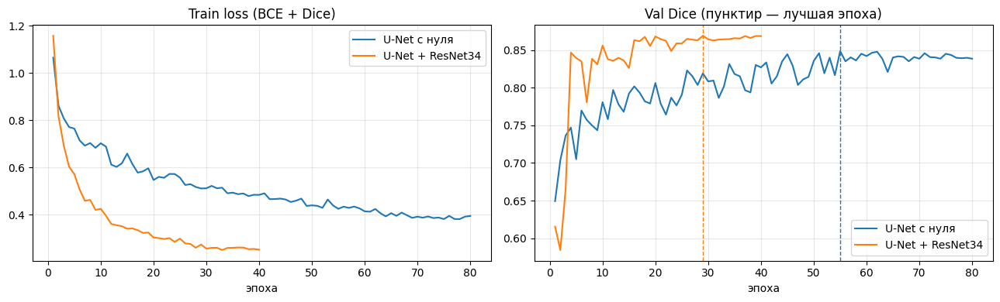

In [23]:
SEG_EPOCHS_SCRATCH = 2 if QUICK else 80
SEG_EPOCHS_PRETRAINED = 2 if QUICK else 40

unet_scratch = UNet()
unet_scratch, hist_scratch, epoch_scratch, sec_scratch = train_segmentation(
    unet_scratch, [{'params': unet_scratch.parameters(), 'lr': 1e-3}], SEG_EPOCHS_SCRATCH, 'U-Net с нуля')

unet_pre = ResNetUNet()
encoder_ids = {id(p) for p in unet_pre.encoder_parameters()}
unet_pre, hist_pre, epoch_pre, sec_pre = train_segmentation(
    unet_pre,
    [{'params': list(unet_pre.encoder_parameters()), 'lr': 1e-4},
     {'params': [p for p in unet_pre.parameters() if id(p) not in encoder_ids], 'lr': 1e-3}],
    SEG_EPOCHS_PRETRAINED, 'U-Net + ResNet34')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, hist, best_ep in [('U-Net с нуля', hist_scratch, epoch_scratch), ('U-Net + ResNet34', hist_pre, epoch_pre)]:
    axes[0].plot(hist['epoch'], hist['train loss'], label=label)
    line, = axes[1].plot(hist['epoch'], hist['val Dice'], label=label)
    axes[1].axvline(best_ep, color=line.get_color(), ls='--', lw=1)
axes[0].set_title('Train loss (BCE + Dice)'); axes[1].set_title('Val Dice (пунктир — лучшая эпоха)')
for ax in axes:
    ax.set_xlabel('эпоха'); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

torch.save(unet_scratch.state_dict(), os.path.join(DATA_DIR, 'unet_scratch_flood.pt'))
torch.save(unet_pre.state_dict(), os.path.join(DATA_DIR, 'unet_resnet34_flood.pt'))

## 2.4. Классические методы сегментации (без нейросетей)

Сравниваем три подхода. У всех одинаковая постобработка: морфологическое открытие и закрытие (убирают мелкий шум и заполняют разрывы), заливка дыр и удаление мелких областей (меньше 1% кадра). В отличие от одного объекта, воды на фото может быть несколько отдельных областей, поэтому оставляем все крупные компоненты, а не только самую большую.

1. **Порог Оцу** по одному цветовому каналу. Оцу выбирает порог, который лучше всего делит гистограмму на 2 группы (максимум межклассовой дисперсии). Какой канал (R, G, B, L\*, a\*, b\*, S, V) и какую сторону порога считать водой, выбираем по Dice на train-снимках — это настройка одного дискретного параметра, без нейросети.
2. **K-means** (k = 3) по цвету в пространстве Lab и координате y. Пиксели группируются по похожести цвета, вертикальная координата (с небольшим весом) делает области связнее. Кластер-вода выбирается автоматически: тот, у которого самый низкий средний y (вода обычно внизу кадра). Для справки считаем и «оракула» — кластер с лучшим Dice по разметке. Это верхняя граница того, что можно выжать из такой кластеризации.
3. **GrabCut** — итеративная сегментация графовыми разрезами: цвета объекта и фона моделируются смесями гауссиан, граница ищется минимальным разрезом графа пикселей. Начальная разметка автоматическая: верхняя треть кадра — «вероятно фон», нижние две трети — «вероятно вода». Дальше GrabCut сам уточняет, какие пиксели внизу на самом деле не вода (дома, деревья), а какие вверху — вода.

In [24]:
import cv2
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu

KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
MIN_AREA = 0.01 * IMG_SIZE * IMG_SIZE


def clean_mask(mask):
    m = cv2.morphologyEx(mask.astype(np.uint8), cv2.MORPH_OPEN, KERNEL)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, KERNEL)
    m = ndi.binary_fill_holes(m).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = [c for c in range(1, n) if stats[c, cv2.CC_STAT_AREA] >= MIN_AREA]
    return np.isin(labels, keep)


def color_channels(image):
    lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return {'R': image[..., 0], 'G': image[..., 1], 'B': image[..., 2],
            'L*': lab[..., 0], 'a*': lab[..., 1], 'b*': lab[..., 2], 'S': hsv[..., 1], 'V': hsv[..., 2]}


def otsu_segment(image, channel, invert):
    values = cv2.GaussianBlur(color_channels(image)[channel].astype(np.float32), (5, 5), 0)
    t = threshold_otsu(values)
    return clean_mask(values < t if invert else values > t)


def kmeans_segment(image, k=3, gt=None, y_weight=30.0):
    lab = cv2.GaussianBlur(cv2.cvtColor(image, cv2.COLOR_RGB2LAB).astype(np.float32), (5, 5), 0)
    h, w = lab.shape[:2]
    yy = np.repeat(np.linspace(0, 1, h, dtype=np.float32)[:, None], w, axis=1)
    X = np.concatenate([lab.reshape(-1, 3), (yy * y_weight).reshape(-1, 1)], axis=1)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 20, 0.5)
    cv2.setRNGSeed(0)
    _, labels, _ = cv2.kmeans(X, k, None, criteria, 3, cv2.KMEANS_PP_CENTERS)
    label_map = labels.reshape(h, w)
    candidates = [clean_mask(label_map == c) for c in range(k)]
    if gt is not None:  # оракул: лучший кластер по разметке
        return max(candidates, key=lambda m: seg_scores(m, gt)['Dice'])
    mean_y = [yy[label_map == c].mean() if (label_map == c).any() else 0 for c in range(k)]
    return candidates[int(np.argmax(mean_y))]


def grabcut_segment(image, iterations=5):
    h = image.shape[0]
    gc_mask = np.full(image.shape[:2], cv2.GC_PR_FGD, np.uint8)
    gc_mask[: h // 3] = cv2.GC_PR_BGD
    bgd, fgd = np.zeros((1, 65), np.float64), np.zeros((1, 65), np.float64)
    cv2.grabCut(cv2.cvtColor(image, cv2.COLOR_RGB2BGR), gc_mask, None, bgd, fgd, iterations, cv2.GC_INIT_WITH_MASK)
    return clean_mask((gc_mask == cv2.GC_FGD) | (gc_mask == cv2.GC_PR_FGD))

In [25]:
# Выбор канала и полярности для порога Оцу по Dice на train
select_idx = idx_train[:30] if QUICK else idx_train
otsu_choice = []
for channel in color_channels(images[0]):
    for invert in (False, True):
        dice = np.mean([seg_scores(otsu_segment(images[i], channel, invert), masks[i])['Dice'] for i in select_idx])
        otsu_choice.append({'канал': channel, 'вода': 'темнее порога' if invert else 'светлее порога',
                            'invert': invert, 'train Dice': dice})
otsu_choice = pd.DataFrame(otsu_choice).sort_values('train Dice', ascending=False)
display(otsu_choice.drop(columns='invert').head(6))
best_channel, best_invert = otsu_choice.iloc[0]['канал'], bool(otsu_choice.iloc[0]['invert'])
print(f"Выбрано: канал {best_channel}, вода {otsu_choice.iloc[0]['вода']}")

,канал,вода,train Dice
0,R,светлее порога,0.678720
6,L*,светлее порога,0.656243
14,V,светлее порога,0.652570
2,G,светлее порога,0.643962
8,a*,светлее порога,0.587038
4,B,светлее порога,0.585572


Выбрано: канал R, вода светлее порога


## 2.5. Сравнение на test

In [26]:
classical = {
    'Порог Оцу': lambda i: otsu_segment(images[i], best_channel, best_invert),
    'K-means (Lab + y, k=3)': lambda i: kmeans_segment(images[i]),
    'GrabCut (авто: низ кадра)': lambda i: grabcut_segment(images[i]),
    'K-means, оракул по разметке*': lambda i: kmeans_segment(images[i], gt=masks[i]),
}

test_masks_pred, per_image, method_time = {}, {}, {}
for name, model in [('U-Net с нуля', unet_scratch), ('U-Net + ResNet34', unet_pre)]:
    start = time.time()
    pred, _ = seg_predict(model, seg_test_loader)
    method_time[name] = (time.time() - start) / len(idx_test)
    test_masks_pred[name] = pred
    per_image[name] = scores_table(pred, idx_test)

for name, fn in classical.items():
    start = time.time()
    preds = [fn(i) for i in tqdm(idx_test, desc=name, leave=False)]
    method_time[name] = (time.time() - start) / len(idx_test)
    test_masks_pred[name] = np.stack(preds)
    per_image[name] = scores_table(preds, idx_test)

comparison = pd.DataFrame({name: scores.mean() for name, scores in per_image.items()}).T
comparison['мс на снимок'] = [method_time[n] * 1000 for n in comparison.index]
comparison['что нужно'] = [f'обучение на {len(idx_train)} размеченных фото, GPU',
                           f'то же + веса ImageNet', '1 параметр выбран на train', 'ничего', 'ничего',
                           'разметка test (только для справки)']
display(comparison.style.format({c: '{:.3f}' for c in ['Dice', 'IoU', 'precision', 'recall', 'pixel acc']})
        .format({'мс на снимок': '{:.1f}'}))
print('* использует разметку test-снимка — это верхняя граница метода, а не честное сравнение.')

Порог Оцу:   0%|          | 0/44 [00:00<?, ?it/s]

K-means (Lab + y, k=3):   0%|          | 0/44 [00:00<?, ?it/s]

GrabCut (авто: низ кадра):   0%|          | 0/44 [00:00<?, ?it/s]

K-means, оракул по разметке*:   0%|          | 0/44 [00:00<?, ?it/s]

,Dice,IoU,precision,recall,pixel acc,мс на снимок,что нужно
U-Net с нуля,0.835100,0.747572,0.878993,0.811309,0.893439,15.8,"обучение на 203 размеченных фото, GPU"
U-Net + ResNet34,0.862379,0.784092,0.871353,0.860469,0.913104,7.3,то же + веса ImageNet
Порог Оцу,0.682509,0.558527,0.632052,0.783697,0.735340,6.7,1 параметр выбран на train
"K-means (Lab + y, k=3)",0.370280,0.287444,0.444910,0.341324,0.586574,66.3,ничего
GrabCut (авто: низ кадра),0.509107,0.371945,0.456254,0.672774,0.527714,726.7,ничего
"K-means, оракул по разметке*",0.715707,0.572112,0.791784,0.689134,0.792568,65.8,разметка test (только для справки)


* использует разметку test-снимка — это верхняя граница метода, а не честное сравнение.


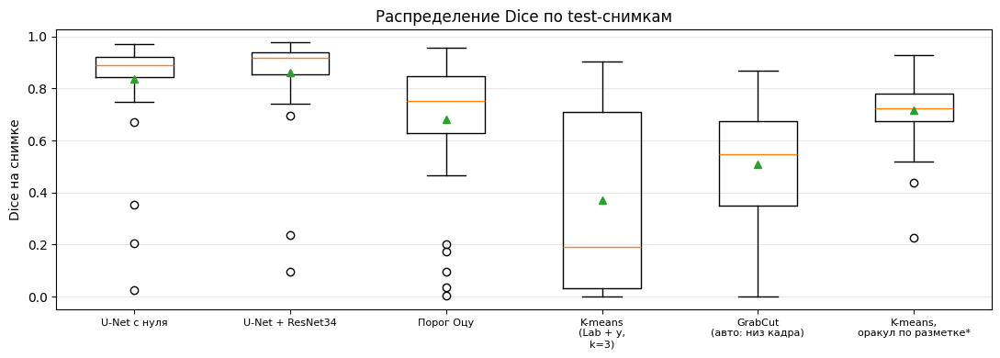

,доля провалов (Dice < 0.5)
U-Net с нуля,7%
U-Net + ResNet34,5%
Порог Оцу,16%
"K-means (Lab + y, k=3)",52%
GrabCut (авто: низ кадра),36%
"K-means, оракул по разметке*",5%


In [27]:
order = list(per_image)
plt.figure(figsize=(11, 4))
plt.boxplot([per_image[n]['Dice'] for n in order], showmeans=True)
plt.xticks(range(1, len(order) + 1), [n.replace(' (', '\n(').replace(', ', ',\n') for n in order], fontsize=8)
plt.ylabel('Dice на снимке'); plt.title('Распределение Dice по test-снимкам'); plt.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

# Доля снимков, где метод фактически не справился (Dice < 0.5)
display(pd.Series({n: (per_image[n]['Dice'] < 0.5).mean() for n in order}, name='доля провалов (Dice < 0.5)')
        .to_frame().style.format('{:.0%}'))

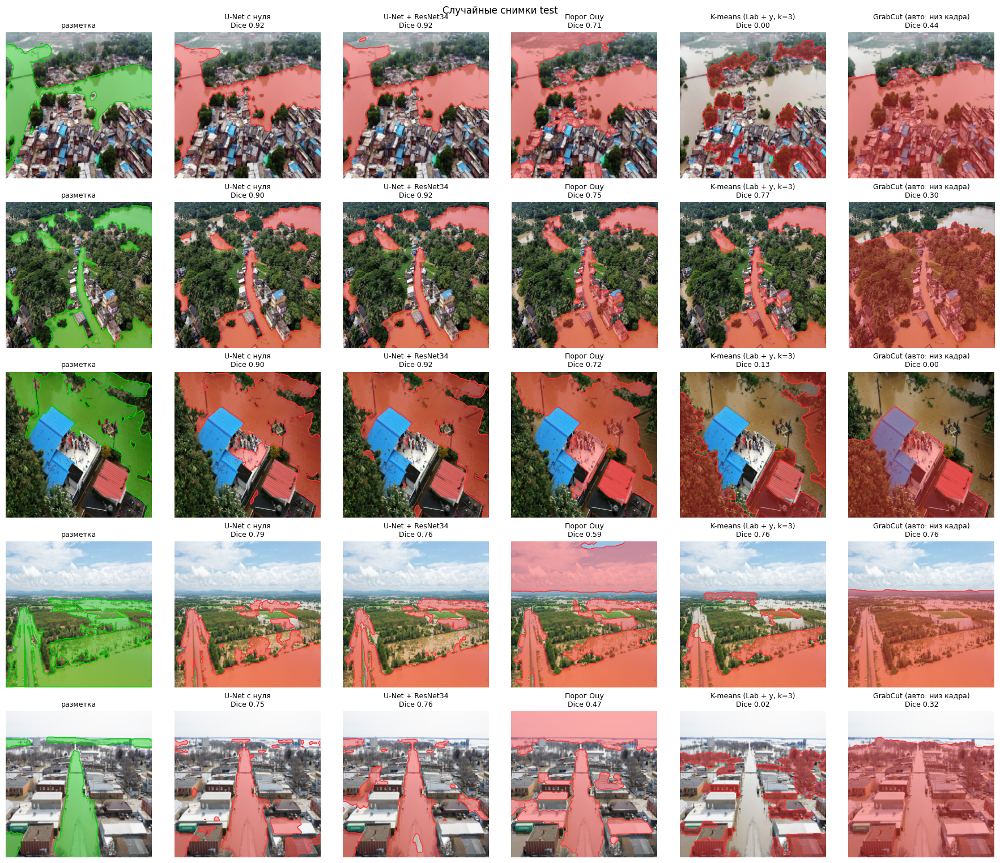

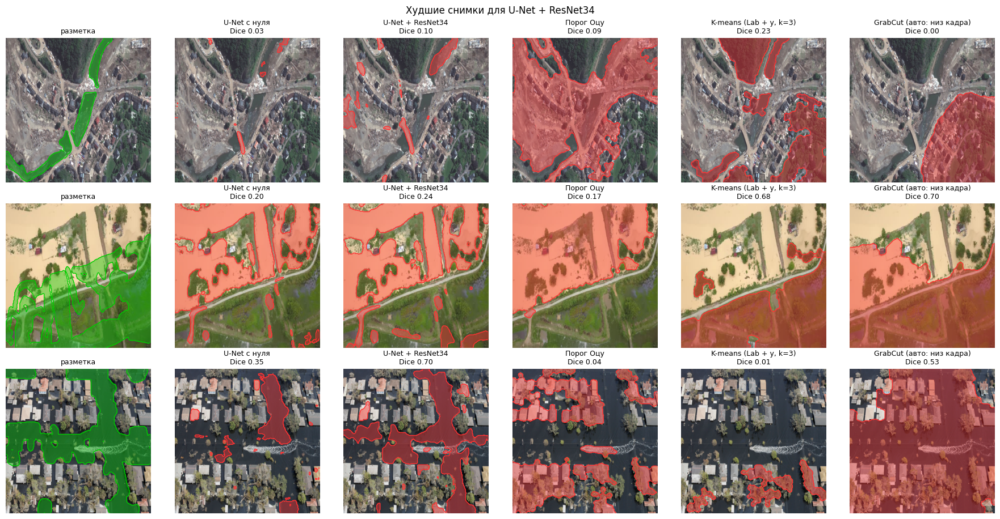

In [28]:
def show_methods(sample_positions, title):
    cols = ['U-Net с нуля', 'U-Net + ResNet34', 'Порог Оцу', 'K-means (Lab + y, k=3)', 'GrabCut (авто: низ кадра)']
    fig, axes = plt.subplots(len(sample_positions), len(cols) + 1,
                             figsize=(3 * (len(cols) + 1), 3.1 * len(sample_positions)), squeeze=False)
    for r, pos in enumerate(sample_positions):
        i = idx_test[pos]
        overlay(axes[r, 0], images[i], masks[i], color=(0, 0.8, 0), title='разметка')
        for c, name in enumerate(cols, start=1):
            d = per_image[name]['Dice'].iloc[pos]
            overlay(axes[r, c], images[i], test_masks_pred[name][pos], color=(1, 0.2, 0.2),
                    title=f'{name}\nDice {d:.2f}')
    fig.suptitle(title)
    plt.tight_layout(); plt.show()


best_unet = max(['U-Net с нуля', 'U-Net + ResNet34'], key=lambda n: per_image[n]['Dice'].mean())
show_methods(np.random.default_rng(3).choice(len(idx_test), 5, replace=False), 'Случайные снимки test')
show_methods(np.argsort(per_image[best_unet]['Dice'].values)[:3], f'Худшие снимки для {best_unet}')

## 2.6. Выводы по заданию 2

| Метод | Dice | IoU | precision | recall | Провалов (Dice < 0.5) | мс на снимок |
|---|---:|---:|---:|---:|---:|---:|
| U-Net с нуля | 0.835 | 0.748 | 0.879 | 0.811 | 7% | 15.8 |
| **U-Net + ResNet34** | **0.862** | **0.784** | 0.871 | **0.860** | **5%** | 7.3 |
| Порог Оцу (канал R) | 0.683 | 0.559 | 0.632 | 0.784 | 16% | 6.7 |
| K-means (Lab + y, k=3) | 0.370 | 0.287 | 0.445 | 0.341 | 52% | 66 |
| GrabCut (авто: низ кадра) | 0.509 | 0.372 | 0.456 | 0.673 | 36% | 727 |
| K-means, оракул по разметке* | 0.716 | 0.572 | 0.792 | 0.689 | 5% | 66 |

\* использует разметку test-снимка — верхняя граница метода, а не честное сравнение.

- **U-Net с нуля** (7.8 млн параметров, как в примере с семинара) даёт на test **Dice 0.835**, IoU 0.748. Обучение — 3.9 мин на T4, лучшая эпоха по val — **55** (val Dice 0.849). После ~60-й эпохи val Dice выходит на плато (0.84), а train loss продолжает снижаться: на 203 фото сеть начинает переобучаться, и дальше эпохи не помогают.
- **U-Net с энкодером ResNet34** (предобученным на ImageNet) — **Dice 0.862**, IoU 0.784, обучение 2.3 мин, лучшая эпоха **29** (val Dice 0.869). Уже на 10-й эпохе val Dice 0.856 — выше, чем U-Net с нуля достигла за 80 эпох. Перенос обучения помогает на маленьком датасете: энкодер уже умеет выделять текстуры и объекты (дома, деревья, небо), и декодеру остаётся научиться собирать из них маску воды. Сильнее всего вырос recall (0.811 → 0.860): сеть с предобученным энкодером находит больше воды, например тёмную воду между домами.
- **Классические методы** без разметки: порог Оцу — Dice **0.683** (лучший канал по train — **R**, вода светлее порога), K-means — **0.370**, GrabCut — **0.509**. Оракул K-means — **0.716**: даже при идеальном выборе кластера цветовая кластеризация не дотягивает до U-Net (0.835–0.862).
- **Почему классика проигрывает.** Цвет воды на фото наводнений сильно различается: коричневая мутная вода похожа на грязь и землю, а в отражениях вода принимает цвет неба и зданий. Порог и кластеризация смотрят только на цвет пикселя (и положение), а U-Net учитывает контекст и текстуру: гладкая однородная поверхность, окружённая домами и деревьями.
- **Где классика работает:** вид сверху на светлую мутную воду, окружённую тёмной зеленью, без неба в кадре — здесь порог Оцу даёт Dice 0.71–0.75, а K-means до 0.77 (близко к U-Net 0.90–0.92).
- **Где классика проваливается:**
  - **Порог Оцу** отмечает водой **небо** (на снимках с горизонтом, Dice 0.47–0.59) и светлые крыши: по каналу R небо, крыши и вода одинаково светлые.
  - **K-means** с правилом «вода — самый нижний кластер» выбирает деревья и дома, если внизу кадра не вода (Dice 0.00–0.13 на половине снимков).
  - **GrabCut** с начальной разметкой «низ кадра — вода» не справляется с видами сверху, где вода занимает весь кадр или внизу дома (Dice 0.00–0.32), и в 100 раз медленнее остальных (0.7 с на снимок).
- **Ошибки U-Net** (худшие снимки): узкая серо-коричневая река на спутниковом снимке почти того же цвета, что и земля (Dice 0.03–0.10); снимок, где размечено затопленное зелёное поле, а сеть выделила бежевую воду/песок (Dice 0.20–0.24; здесь K-means и GrabCut случайно оказались лучше — 0.68–0.70); тёмная вода между домами (с нуля Dice 0.35, с ResNet34 — 0.70). Всё это — случаи, когда вода не похожа на типичную коричневую воду наводнения из train.
- **Цена.** Классические методы не требуют разметки и GPU; порог Оцу работает за 6.7 мс на снимок, но GrabCut — 0.7 с. U-Net требует 203 размеченных фото и несколько минут обучения на GPU, зато точнее на 18–49 п.п. Dice и на GPU работает так же быстро (7–16 мс на снимок).